In [2]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("data/USvideos.csv", encoding="utf-8")

with open("data/US_category_id.json", "r", encoding="utf-8") as file:
    category_data = json.load(file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (40949, 16)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


In [4]:
category_mapping = {
    int(item["id"]): item["snippet"]["title"]
    for item in category_data["items"]
}

df["category_id"] = pd.to_numeric(
    df["category_id"], errors="coerce"
).astype("Int64")

df["category_name"] = df["category_id"].map(category_mapping)

display(df[["category_id", "category_name"]].head())

,category_id,category_name
0,22,People & Blogs
1,24,Entertainment
2,23,Comedy
3,24,Entertainment
4,24,Entertainment


In [5]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique videos:", df["video_id"].nunique())

Dataset shape: (40949, 17)

Data types:
video_id                  object
trending_date             object
title                     object
channel_title             object
category_id                Int64
publish_time              object
tags                      object
views                      int64
likes                      int64
dislikes                   int64
comment_count              int64
thumbnail_link            object
comments_disabled           bool
ratings_disabled            bool
video_error_or_removed      bool
description               object
category_name             object
dtype: object

Missing values:
video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments

In [6]:
df["trending_date"] = pd.to_datetime(
    df["trending_date"],
    format="%y.%d.%m",
    errors="coerce"
)

df["publish_time"] = pd.to_datetime(
    df["publish_time"],
    utc=True,
    errors="coerce"
).dt.tz_localize(None)

print(df[["trending_date", "publish_time"]].head())

  trending_date        publish_time
0    2017-11-14 2017-11-13 17:13:01
1    2017-11-14 2017-11-13 07:30:00
2    2017-11-14 2017-11-12 19:05:24
3    2017-11-14 2017-11-13 11:00:04
4    2017-11-14 2017-11-12 18:01:41


In [7]:
df = df.sort_values("trending_date")

df = df.drop_duplicates(
    subset="video_id",
    keep="first"
).copy()

df = df.reset_index(drop=True)

print("Shape after removing repeated video appearances:", df.shape)
print("Unique video IDs:", df["video_id"].nunique())

Shape after removing repeated video appearances: (6351, 17)
Unique video IDs: 6351


In [8]:
df = df[df["views"] > 0].copy()

# Engagement metrics
df["engagement_rate"] = (
    (df["likes"] + df["dislikes"] + df["comment_count"])
    / df["views"]
) * 100

df["like_rate"] = (df["likes"] / df["views"]) * 100

df["dislike_rate"] = (df["dislikes"] / df["views"]) * 100

# Time between publication and first trending appearance
df["days_to_trend"] = (
    df["trending_date"] - df["publish_time"]
).dt.total_seconds() / 86400

display(
    df[
        [
            "video_id",
            "views",
            "likes",
            "dislikes",
            "comment_count",
            "engagement_rate",
            "like_rate",
            "dislike_rate",
            "days_to_trend",
        ]
    ].head()
)

,video_id,views,likes,dislikes,comment_count,engagement_rate,like_rate,dislike_rate,days_to_trend
0,2kyS6SvSYSE,748374,57527,2966,15954,10.215080,7.686932,0.396326,0.282627
1,htvR_dBs3eg,98422,2926,106,798,3.891406,2.972913,0.107699,3.097951
2,qEEtzzi1EII,426078,19323,245,945,4.814377,4.535085,0.057501,4.434051
3,1Wk8ZRgXQnY,33315,1365,24,91,4.442443,4.097253,0.072040,4.064063
4,8l_e6bx8UG8,1231518,32648,6221,9288,3.910377,2.651037,0.505149,5.291667


In [9]:
print("New columns:")
print(
    df[
        [
            "engagement_rate",
            "like_rate",
            "dislike_rate",
            "days_to_trend",
        ]
    ].describe()
)

print("\nMissing values in new metrics:")
print(
    df[
        [
            "engagement_rate",
            "like_rate",
            "dislike_rate",
            "days_to_trend",
        ]
    ].isnull().sum()
)

New columns:
       engagement_rate    like_rate  dislike_rate  days_to_trend
count      6351.000000  6351.000000   6351.000000    6351.000000
mean          4.764768     4.028288      0.172006      21.943379
std           3.898611     3.490346      0.444790     209.965703
min           0.000000     0.000000      0.000000      -0.541713
25%           1.924750     1.439044      0.051818       0.457529
50%           3.802762     3.141512      0.091269       1.102269
75%           6.405392     5.536296      0.166489       2.115503
max          33.025531    29.046646     19.153148    4214.649873

Missing values in new metrics:
engagement_rate    0
like_rate          0
dislike_rate       0
days_to_trend      0
dtype: int64


In [10]:
# Check videos with negative days_to_trend
negative_days = df[df["days_to_trend"] < 0]

print("Videos with negative days_to_trend:", len(negative_days))

display(
    negative_days[
        ["video_id", "title", "trending_date", "publish_time", "days_to_trend"]
    ].head(10)
)

# Inspect the 10 largest time gaps
display(
    df.nlargest(10, "days_to_trend")[
        ["video_id", "title", "trending_date", "publish_time", "days_to_trend"]
    ]
)

Videos with negative days_to_trend: 119


,video_id,title,trending_date,publish_time,days_to_trend
221,vZzIS17HexE,Taylor Swift Instagram Story - Target 11/14/17,2017-11-15,2017-11-15 03:11:17,-0.132836
239,xL_qpDkF5A8,American Crime Story Season 2: The Assassinati...,2017-11-15,2017-11-15 01:25:18,-0.059236
240,eQVhAN7-IAw,The Making of a Song: “Delicate” – watch more ...,2017-11-15,2017-11-15 03:43:47,-0.155405
331,U5sCjnezw4o,Jaylen Brown delivers emotional press conferen...,2017-11-17,2017-11-17 04:20:40,-0.181019
347,TyHvyGVs42U,"Luis Fonsi, Demi Lovato - Échame La Culpa",2017-11-17,2017-11-17 05:00:01,-0.208345
447,jGyUVyp9w9g,Chance-giving Monologue - SNL,2017-11-19,2017-11-19 05:43:25,-0.238484
475,UhZ56rcWwRQ,A Wrinkle in Time Official US Trailer,2017-11-20,2017-11-20 01:22:15,-0.057118
482,n6xzsLDzyBk,Lady Gaga - The Cure (Live at AMA's from Joann...,2017-11-20,2017-11-20 02:45:15,-0.114757
485,WXlr35jV3cw,P!nk presentation on AMAs 2017,2017-11-20,2017-11-20 03:10:33,-0.132326
578,0dSR-9mtuzk,The Voice 2017 - Pitch Perfect 3 x The Voice F...,2017-11-22,2017-11-22 01:30:05,-0.062558


,video_id,title,trending_date,publish_time,days_to_trend
3567,MJO3FmmFuh4,Budweiser - Original Whazzup? ad,2018-02-05,2006-07-23 08:24:11,4214.649873
2290,UQtt9I6c-YM,Kramer vs Kramer-Clou Scene,2018-01-06,2008-04-05 18:22:40,3562.234259
682,wFEAoF7RC7Y,Behind The Sounds: That's Not Me,2017-11-25,2008-06-17 00:07:56,3447.994491
701,Y8JGfi4MJ8k,SAOIRSE RONAN - MORONIC (IRONIC),2017-11-26,2008-08-07 12:16:58,3397.488218
425,rO_mAQC9bv0,Amazon.com commercial Xmas 1999Magnetic Whale Art,2017-11-19,2009-03-10 00:27:20,3175.981019
1597,2vQ_fnlvvr8,The Smithereens - Blue Period,2017-12-16,2009-06-08 01:55:32,3112.919769
2769,tYFYoLEO0dM,The Cranberries - Dreams (Music Video HQ),2018-01-18,2009-09-18 15:36:33,3043.349618
2469,c_KdAO6MqiM,TimRollins part1,2018-01-12,2009-09-29 16:27:28,3026.314259
2004,-37nIo_tLnk,Christmas Day 2000,2017-12-26,2009-12-15 23:26:32,2932.023241
247,qC0I5PEhkJo,The perfect ice - Ice boats on Lake Geneva,2017-11-15,2010-01-14 15:56:31,2861.335752


In [11]:
# Calculate the difference in calendar days
df["days_to_trend"] = (
    df["trending_date"].dt.normalize()
    - df["publish_time"].dt.normalize()
).dt.days

print(df["days_to_trend"].describe())

print(
    "Videos with negative days_to_trend:",
    (df["days_to_trend"] < 0).sum()
)

count    6351.000000
mean       22.520548
std       209.963344
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max      4215.000000
Name: days_to_trend, dtype: float64
Videos with negative days_to_trend: 0


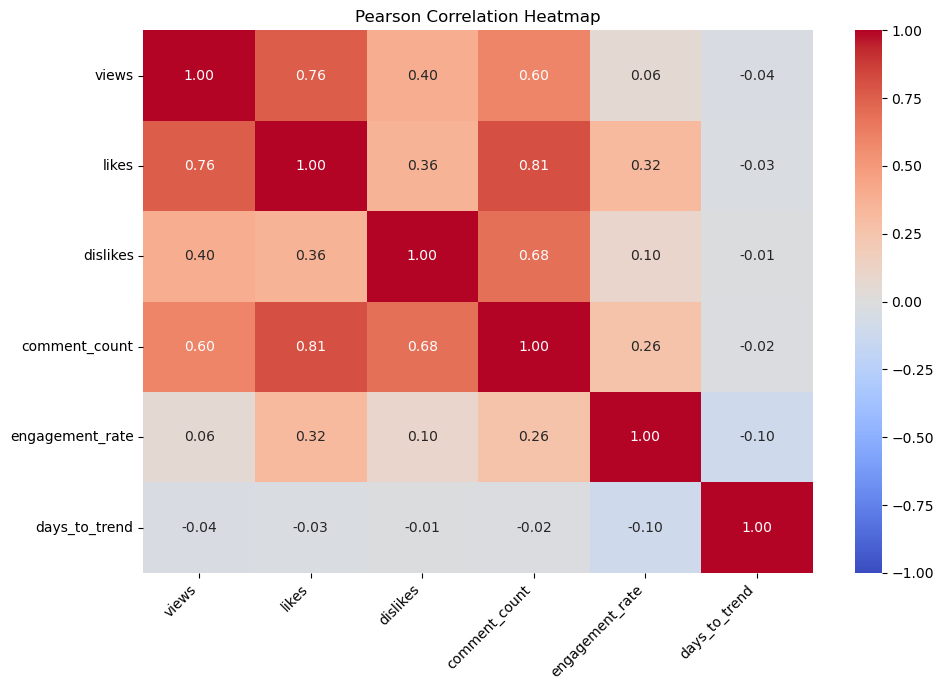

In [12]:
correlation_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count",
    "engagement_rate",
    "days_to_trend"
]

correlation_matrix = df[correlation_columns].corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Heatmap")

# Rotate axis labels for better readability
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("visuals/pearson_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
category_performance = (
    df.groupby("category_name")
    .agg(
        avg_views=("views", "mean"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_like_rate=("like_rate", "mean"),
        video_count=("video_id", "count")
    )
    .sort_values("avg_views", ascending=False)
    .round(2)
)

display(category_performance)

,avg_views,avg_engagement_rate,avg_like_rate,video_count
category_name,,,,
Music,1387621.18,8.23,7.40,799
Gaming,1211843.80,5.48,4.38,103
Nonprofits & Activism,1025216.57,4.83,3.74,14
Film & Animation,920433.03,4.03,3.40,318
Sports,830281.53,2.04,1.61,451
Entertainment,817124.20,3.84,3.20,1619
Comedy,772954.61,5.69,4.97,547
People & Blogs,712767.50,5.51,4.70,498
Science & Technology,584322.49,4.23,3.58,380


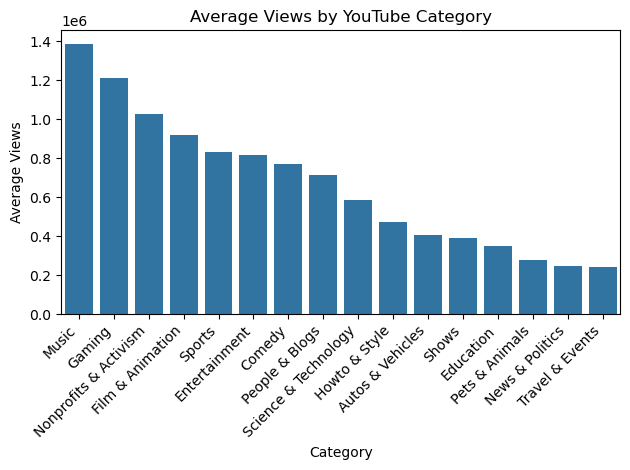

In [14]:
category_views = category_performance.sort_values(
    "avg_views", ascending = False
)

sns.barplot(
    data = category_views.reset_index(),
    x = "category_name",
    y = "avg_views"
)

plt.title("Average Views by YouTube Category")
plt.xlabel("Category")
plt.ylabel("Average Views")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visuals/average_views_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

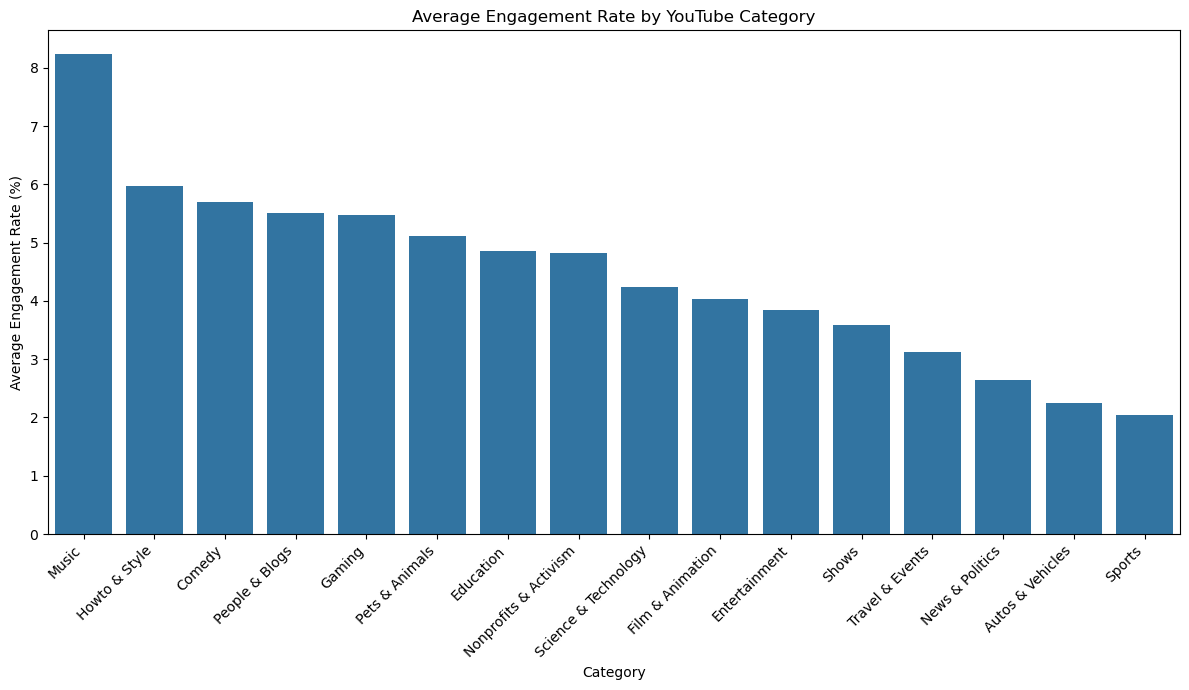

In [ ]:
plt.figure(figsize =(12,7))

ca
tegory_engagement = category_performance.sort_values(
    "avg_engagement_rate", ascending= False
    )

sns.barplot(
    data = category_engagement.reset_index(),
    x = "category_name",
    y= "avg_engagement_rate"
)



plt.title("Average Engagement Rate by YouTube Category")
plt.xlabel("Category")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visuals/engagement_rate_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
df["publish_weekday"] = df["publish_time"].dt.day_name()


weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_views = (
    df.groupby("publish_weekday")["views"]
    .mean()
    .reindex(weekday_order)
)

display(weekday_views.to_frame("average_views").round(2))

,average_views
publish_weekday,
Monday,750340.86
Tuesday,722556.56
Wednesday,677738.52
Thursday,713014.40
Friday,894334.04
Saturday,726031.16
Sunday,859492.58


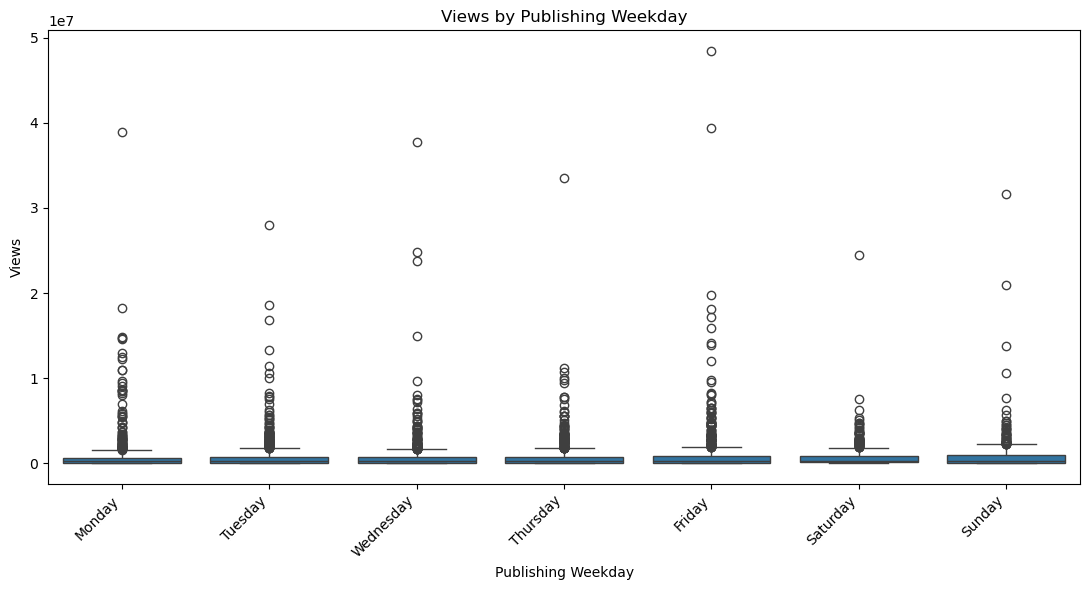

In [18]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="publish_weekday",
    y="views",
    order=weekday_order
)

plt.title("Views by Publishing Weekday")
plt.xlabel("Publishing Weekday")
plt.ylabel("Views")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig("visuals/views_by_publish_weekday.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
weekday_comparison = (
    df.groupby("publish_weekday")["views"]
    .agg(
        average_views="mean",
        median_views="median",
        video_count="count"
    )
    .reindex(weekday_order)
    .round(2)
)

display(weekday_comparison)

,average_views,median_views,video_count
publish_weekday,,,
Monday,750340.86,254444.0,985
Tuesday,722556.56,250242.0,1061
Wednesday,677738.52,268548.0,1097
Thursday,713014.40,291258.0,1055
Friday,894334.04,264767.0,1047
Saturday,726031.16,288208.0,547
Sunday,859492.58,296633.0,559


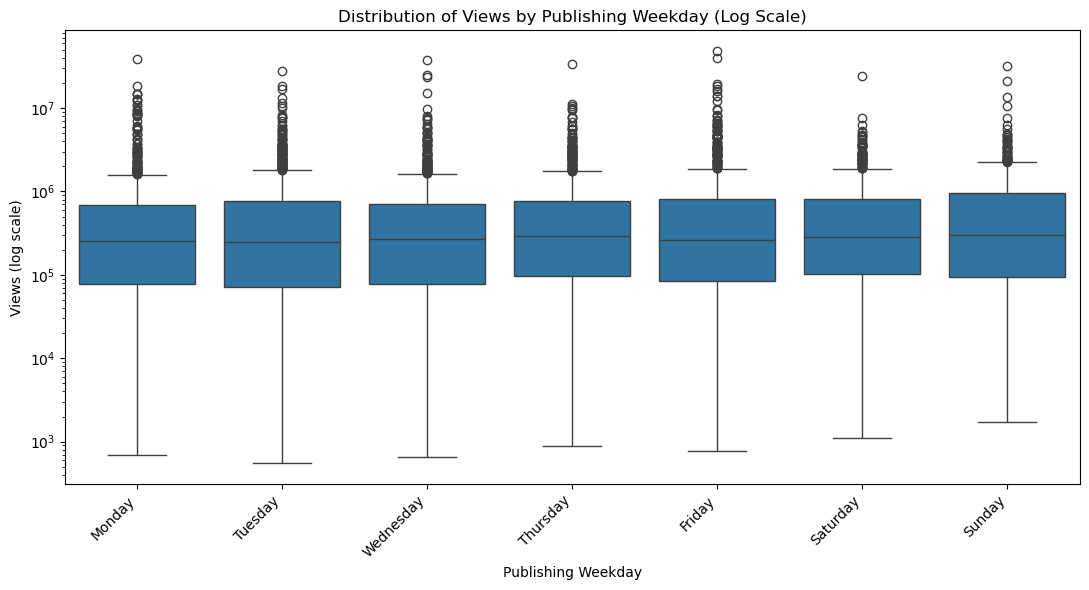

In [ ]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df[df["views"] > 0],
    x="publish_weekday",
    y="views",
    order=weekday_order
)

plt.yscale("log")
plt.title("Distribution of Views by Publishing Weekday (Log Scale)")
plt.xlabel("Publishing Weekday")
plt.ylabel("Views (log scale)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig("visuals/views_by_publish_weekday_log.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
top_10_videos = (
    df.nlargest(10, "views")[
        [
            "title",
            "channel_title",
            "category_name",
            "views",
            "engagement_rate",
            "like_rate",
            "days_to_trend"
        ]
    ]
    .reset_index(drop=True)
)

display(top_10_videos)

,title,channel_title,category_name,views,engagement_rate,like_rate,days_to_trend
0,Maluma - El Préstamo (Official Video),MalumaVEVO,Music,48431654,1.425787,1.257651,6
1,BTS (방탄소년단) 'FAKE LOVE' Official MV,ibighit,Music,39349927,11.804553,9.860427,1
2,TWICE What is Love? M/V,jypentertainment,Music,38873543,3.639059,2.859508,5
3,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,Entertainment,37736281,5.297557,4.600069,1
4,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,Music,33523622,5.191184,4.874545,5
5,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,Music,31648454,5.075682,4.440517,2
6,VENOM - Official Trailer (HD),Sony Pictures Entertainment,Entertainment,27973210,3.480723,3.039916,1
7,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,Entertainment,24782158,8.454518,4.637147,1
8,Drake - Nice For What,DrakeVEVO,Music,24421448,2.870477,2.626978,7
9,Sanju | Official Trailer | Ranbir Kapoor | Raj...,FoxStarHindi,Entertainment,23758250,2.735273,2.472093,2


In [27]:
# 1. Correlation between views and likes
views_likes_corr = df["views"].corr(df["likes"], method="pearson")

# 2. Correlation between comments and dislikes
comments_dislikes_corr = df["comment_count"].corr(
    df["dislikes"], method="pearson"
)

# 3. Correlation between tags count and views
df["tags_count"] = df["tags"].apply(
    lambda x: 0 if x == "[none]" else len(x.split("|"))
)

tags_views_corr = df["tags_count"].corr(df["views"], method="pearson")

print(f"Views vs. likes: r = {views_likes_corr:.2f}")
print(f"Comments vs. dislikes: r = {comments_dislikes_corr:.2f}")
print(f"Tags count vs. views: r = {tags_views_corr:.2f}")

Views vs. likes: r = 0.76
Comments vs. dislikes: r = 0.68
Tags count vs. views: r = 0.04


In [32]:
category_metrics = (
    df.groupby("category_name")
    .agg(
        avg_views=("views", "mean"),
        avg_engagement_rate=("engagement_rate", "mean"),
        video_count=("video_id", "count")
    )
    .sort_values("avg_engagement_rate", ascending=False)
)

display(category_metrics.round(2))

print("\nHighest average engagement:")
print(category_metrics["avg_engagement_rate"].idxmax())

print("\nHighest average views:")
print(category_metrics["avg_views"].idxmax())

,avg_views,avg_engagement_rate,video_count
category_name,,,
Music,1387621.18,8.23,799
Howto & Style,473138.93,5.97,595
Comedy,772954.61,5.69,547
People & Blogs,712767.50,5.51,498
Gaming,1211843.80,5.48,103
Pets & Animals,280104.36,5.12,138
Education,351979.46,4.85,250
Nonprofits & Activism,1025216.57,4.83,14
Science & Technology,584322.49,4.23,380



Highest average engagement:
Music

Highest average views:
Music


In [33]:
weekday_engagement = (
    df.groupby("publish_weekday")["engagement_rate"]
    .agg(["mean", "median", "count"])
    .reindex(weekday_order)
    .round(2)
)

display(weekday_engagement)

print(
    "\nLowest average engagement weekday:",
    weekday_engagement["mean"].idxmin()
)

,mean,median,count
publish_weekday,,,
Monday,4.38,3.44,985
Tuesday,4.57,3.68,1061
Wednesday,4.76,3.78,1097
Thursday,5.02,3.99,1055
Friday,5.24,4.06,1047
Saturday,4.88,4.13,547
Sunday,4.32,3.41,559



Lowest average engagement weekday: Sunday


In [28]:
#Bonus
views_median = df["views"].median()
engagement_median = df["engagement_rate"].median()

high_views_low_engagement = df[
    (df["views"] >= views_median) &
    (df["engagement_rate"] < engagement_median)
].sort_values("views", ascending=False)

high_engagement_low_views = df[
    (df["views"] < views_median) &
    (df["engagement_rate"] >= engagement_median)
].sort_values("engagement_rate", ascending=False)

print("High views, low engagement:")
display(
    high_views_low_engagement[
        ["title", "category_name", "views", "engagement_rate"]
    ].head(10).round(2)
)

print("High engagement, lower views:")
display(
    high_engagement_low_views[
        ["title", "category_name", "views", "engagement_rate"]
    ].head(10).round(2)
)

High views, low engagement:


,title,category_name,views,engagement_rate
4770,Maluma - El Préstamo (Official Video),Music,48431654,1.43
5322,TWICE What is Love? M/V,Music,38873543,3.64
5538,VENOM - Official Trailer (HD),Entertainment,27973210,3.48
5316,Drake - Nice For What,Music,24421448,2.87
6189,Sanju | Official Trailer | Ranbir Kapoor | Raj...,Entertainment,23758250,2.74
3575,To Our Daughter,People & Blogs,20921796,0.00
5540,Sanju | Official Teaser | Ranbir Kapoor | Rajk...,Entertainment,18639195,3.00
1274,Jurassic World: Fallen Kingdom - Official Trai...,Entertainment,18184886,2.62
5967,Do You Hear Yanny or Laurel? (SOLVED with SCIE...,Science & Technology,15006579,2.54
4150,Fergie Performs The U.S. National Anthem / 201...,Sports,14647590,1.33


High engagement, lower views:


,title,category_name,views,engagement_rate
3183,dodie - Secret For The Mad,Music,129130,27.74
4522,"In Loving Memory of,",People & Blogs,45886,24.68
1327,Idol EXPOSES Dark Side of KPOP | STORYTIME exp...,People & Blogs,35704,24.51
3138,Lady Gaga - Joanne (Where Do You Think You’re ...,Music,208114,22.73
560,How to do a beauty Vlog for Tarte Cosmetics,Entertainment,38219,22.70
1605,dodie - In The Middle,Music,236457,22.40
1291,Liam Payne - Bedroom Floor (Live Acoustic),Music,243001,22.35
2847,Remy Ma - Melanin Magic (Pretty Brown) (Audio)...,Music,9477,21.36
2622,THINGS THAT ARE LOWER,Entertainment,109642,21.10
2617,The Vamps - Same To You (Acoustic),Music,91620,20.66


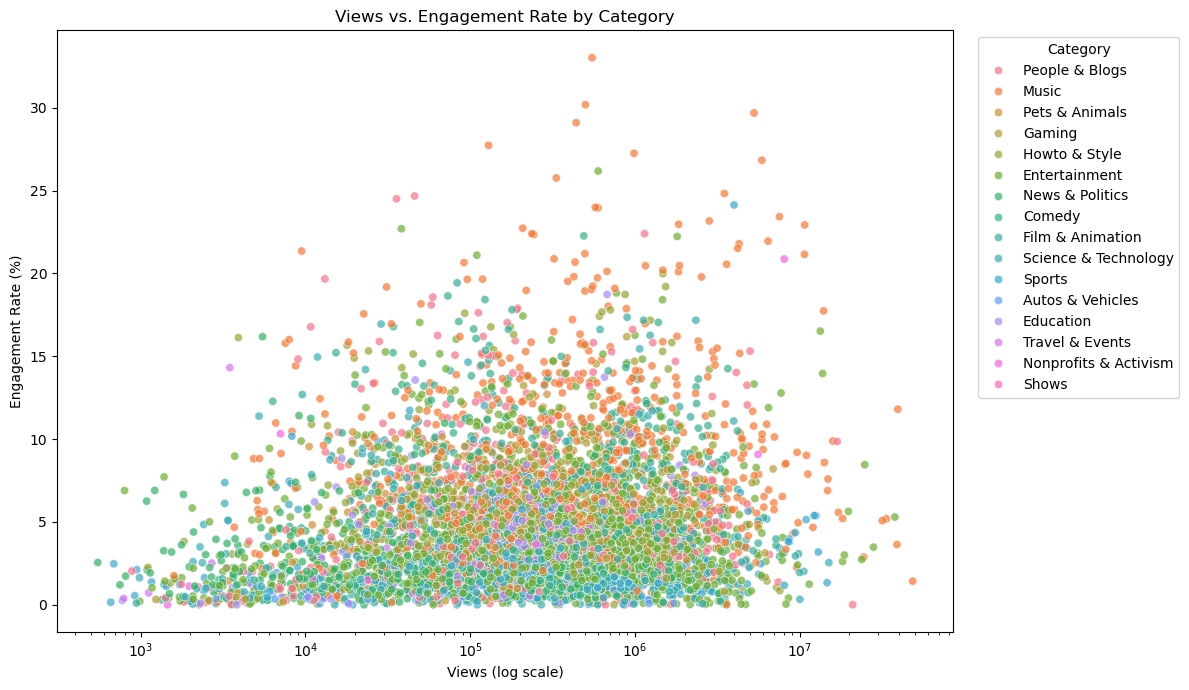

In [29]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="views",
    y="engagement_rate",
    hue="category_name",
    alpha=0.7
)

plt.xscale("log")
plt.title("Views vs. Engagement Rate by Category")
plt.xlabel("Views (log scale)")
plt.ylabel("Engagement Rate (%)")
plt.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig("visuals/views_vs_engagement_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

# Final Conclusion

## Project Summary

This project explored engagement patterns and correlations in YouTube trending videos using data analysis and visualization techniques. The dataset was cleaned and processed before examining relationships between video metrics, category performance, publication weekdays, and audience engagement.

## Key Insights

- **Views and likes:** A strong positive correlation was observed between views and likes (\(r = 0.76\)).
- **Comments and dislikes:** These metrics showed a positive correlation (\(r = 0.68\)), suggesting that videos receiving more comments also tend to receive more dislikes.
- **Tags and views:** The correlation was almost zero (\(r = 0.04\)), indicating little linear relationship between the number of tags and views.
- **Category performance:** Music had the highest average views and average engagement rate among the analyzed categories.
- **Publication weekday:** Friday recorded the highest average engagement rate (5.24%), while Sunday had the lowest (4.32%).
- **Popularity versus engagement:** A high number of views does not necessarily mean that a video has a high engagement rate.

## Limitations

This analysis focuses on the available trending-video dataset and does not establish causal relationships. The results may be influenced by factors such as channel popularity, video content, audience demographics, and publication timing. Some categories also contain relatively few videos, which limits the reliability of their average metrics.

## Final Thoughts

This project demonstrated how data cleaning, exploratory data analysis, correlation analysis, grouping, and visualization can be used to investigate audience behavior and content performance on YouTube.

The findings highlight the importance of examining multiple metrics rather than relying on views alone. Combining popularity measures with engagement rates provides a more comprehensive understanding of how audiences interact with trending content.

Further analysis could explore relationships between video duration, tags, upload timing, and engagement, as well as develop predictive models to estimate video performance.

**Overall, this project strengthened my understanding of data analysis and demonstrated how data-driven insights can support more informed decisions about digital content performance.**

## 5 Key Insights

### 1. Views and Likes Are Strongly Correlated
The correlation between views and likes was **0.76**, indicating a strong positive relationship. Videos with more views generally tend to receive more likes, although this does not establish causation.

### 2. Music Leads in Both Popularity and Engagement
The Music category recorded the highest average views (**1.39 million**) and the highest average engagement rate (**8.23%**) among the analyzed categories. This suggests strong performance in both reach and audience interaction within this dataset.

### 3. High Popularity Does Not Always Mean High Engagement
Some of the most-viewed videos had relatively low engagement rates. For example, *Maluma – El Préstamo* received approximately **48.43 million views** but had an engagement rate of about **1.43%**. This demonstrates that reach and audience interaction measure different aspects of performance.

### 4. Engagement Varies by Publication Weekday
Friday had the highest average engagement rate (**5.24%**), while Sunday had the lowest (**4.32%**). Although this pattern may be useful when exploring upload strategies, the analysis does not prove that publication weekday directly influences engagement.

### 5. The Number of Tags Has Little Linear Relationship with Views
The correlation between the number of tags and views was only **0.04**, indicating almost no linear relationship in this dataset. Therefore, simply adding more tags was not associated with higher view counts in this analysis.

In [30]:
df.to_csv("output_data/cleaned_youtube_data.csv", index=False)

In [31]:
category_performance.to_csv("output_data/category_performance.csv")

weekday_comparison.to_csv("output_data/weekday_comparison.csv")

top_10_videos.to_csv("output_data/top_10_videos.csv", index=False)